# 01 — Data Loading, Preprocessing, and Exploratory Analysis

Split from `WindForecasting.ipynb`. Contents: project paths, raw wind and operational datasets, datetime construction, data-quality audit, exploratory analysis (distribution, monthly and hourly patterns, stationarity), chronological 70/15/15 split, and the 168 h → 24 h supervised windowing with train-only standardization used by every forecasting model.

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
from rich.jupyter import display

# ============================================================
# PROJECT PATHS
# ============================================================

CURRENT_DIR = Path.cwd()

# Walk upward until a folder containing the raw wind dataset is found,
# so this notebook works from Data/Microgrid-Forecasting-Stochastic-
# Optimization/notebooks as well as from Data/notebooks. If the raw
# data is later copied into this repository's data/raw, the repository
# root is used automatically.
_candidates = [CURRENT_DIR, *CURRENT_DIR.parents]
PROJECT_ROOT = None
for candidate in _candidates:
    if (candidate / "data" / "raw" / "agregatenew.csv").exists():
        PROJECT_ROOT = candidate
        break
if PROJECT_ROOT is None:
    # GitHub clone: raw data absent, derived inputs distributed
    for candidate in _candidates:
        if (candidate / "data" / "optimization_input"
                / "pgu_parameters.csv").exists():
            PROJECT_ROOT = candidate
            break
if PROJECT_ROOT is None:
    PROJECT_ROOT = CURRENT_DIR

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
OPT_INPUT_DIR = PROJECT_ROOT / "data" / "optimization_input"
OPT_OUTPUT_DIR = PROJECT_ROOT / "data" / "optimization_output"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "figures"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data: {RAW_DIR}")

Project root: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data
Raw data: /Volumes/Expansion/01_Resarch/Research in Progress/Prophet/Data/data/raw


In [4]:
WIND_FILE = RAW_DIR / "agregatenew.csv"
OPERATIONAL_FILE = RAW_DIR / "Renewable_energy_dataset.csv"

wind_df = pd.read_csv(WIND_FILE)
operational_df = pd.read_csv(OPERATIONAL_FILE)

print("Wind dataset:", wind_df.shape)
print("Operational dataset:", operational_df.shape)

Wind dataset: (8375, 22)
Operational dataset: (3546, 10)


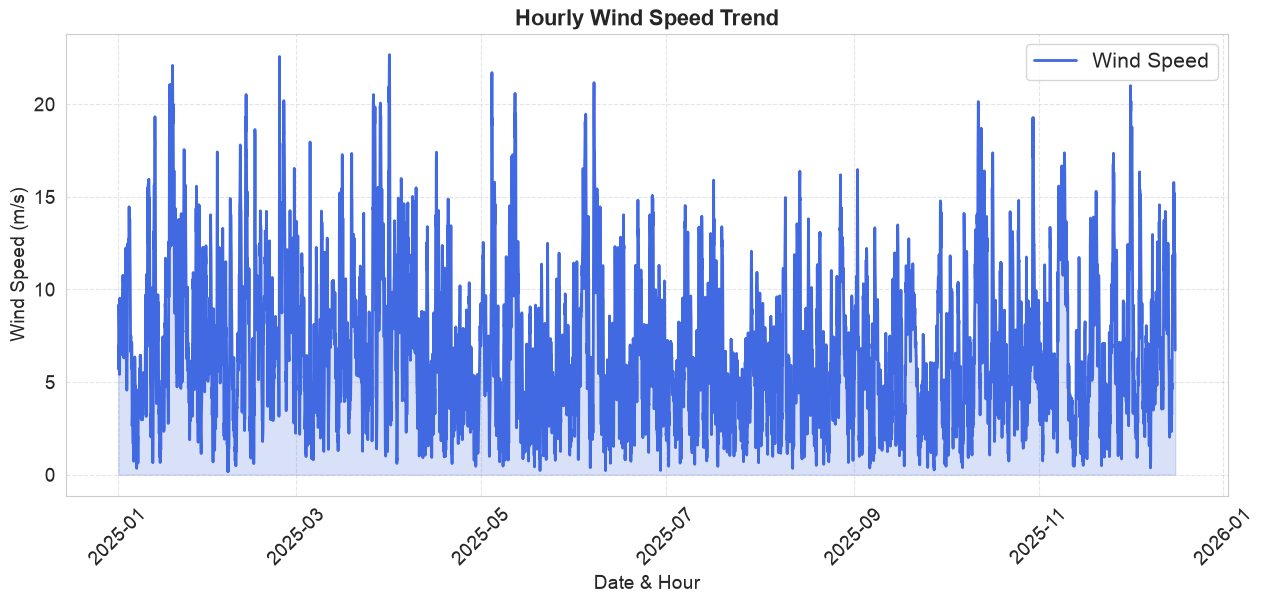

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(WIND_FILE)  # Update path if needed


# Convert month, day, and hour into a proper datetime format
df["datetime"] = pd.to_datetime(
    "2025-" + df["month"].astype(str) + "-" + df["day"].astype(str) + " " + df["hour"].astype(str) + ":00:00"
)

# Sort by datetime to ensure correct ordering
df = df.sort_values(by="datetime")

# Set up the figure
plt.figure(figsize=(15, 6))
sns.set_style("whitegrid")

# Plot the wind speed data with hourly granularity
# sns.lineplot(x=df["datetime"], y=df["windSpeed"], label="Wind Speed", linewidth=1.5, color="royalblue", marker="o")

# Create the plot
sns.lineplot(x=df["datetime"], y=df["windSpeed"], label="Wind Speed", linewidth=2, color="royalblue")
plt.fill_between(df["datetime"], df["windSpeed"], color='royalblue', alpha=0.2)

# Enhance visualization
plt.title("Hourly Wind Speed Trend", fontsize=16, fontweight='bold')
plt.xlabel("Date & Hour", fontsize=14)
plt.ylabel("Wind Speed (m/s)", fontsize=14)
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Show the plot
plt.show()

Dataset shape: (8375, 22)

Columns:
['month', 'day', 'hour', 'use', 'gen', 'Machine', 'Machine_1', 'Machine_2', 'Machine_3', 'well_use', 'Machine_4', 'furnace_use', 'Depot', 'barn_use', 'Office_2', 'temperature', 'humidity', 'visibility', 'pressure', 'windSpeed', 'windBearing', 'precipIntensity']

First observations:


,month,day,hour,use,gen,Machine,Machine_1,Machine_2,Machine_3,well_use,...,Depot,barn_use,Office_2,temperature,humidity,visibility,pressure,windSpeed,windBearing,precipIntensity
0,1,1,5,62.647783,0.198417,0.016411,0.003817,2.271667,3.801033,0.062533,...,0.782767,2.332833,0.090283,36.131000,0.619667,10.0,1016.888,9.150333,282.100000,0.0
1,1,1,6,55.090017,0.205300,0.014972,0.005950,4.531317,6.776500,0.061250,...,0.770167,2.350883,0.097083,35.838667,0.610000,10.0,1016.232,8.284000,284.733333,0.0
2,1,1,7,42.884167,0.206900,0.014528,0.002550,3.569133,0.431050,0.060833,...,0.797917,2.066350,0.097717,35.385000,0.613000,10.0,1015.989,7.927000,279.400000,0.0
3,1,1,8,57.600767,0.206850,0.016111,0.008300,3.624717,0.422683,0.060983,...,0.775517,2.051700,0.098067,35.282000,0.640000,10.0,1016.042,5.684667,265.000000,0.0
4,1,1,9,38.390183,0.206350,0.015917,0.003617,2.106350,0.428567,0.060817,...,0.793200,1.909783,0.099000,35.451667,0.641667,10.0,1015.815,6.975000,265.500000,0.0



Data types:
month                int64
day                  int64
hour                 int64
use                float64
gen                float64
Machine            float64
Machine_1          float64
Machine_2          float64
Machine_3          float64
well_use           float64
Machine_4          float64
furnace_use        float64
Depot              float64
barn_use           float64
Office_2           float64
temperature        float64
humidity           float64
visibility         float64
pressure           float64
windSpeed          float64
windBearing        float64
precipIntensity    float64
dtype: object
Date range:
2025-01-01 05:00:00 to 2025-12-16 03:00:00

Total observations:
8375

Missing values:
month              0
day                0
hour               0
use                0
gen                0
Machine            0
Machine_1          0
Machine_2          0
Machine_3          0
well_use           0
Machine_4          0
furnace_use        0
Depot              0
barn_use

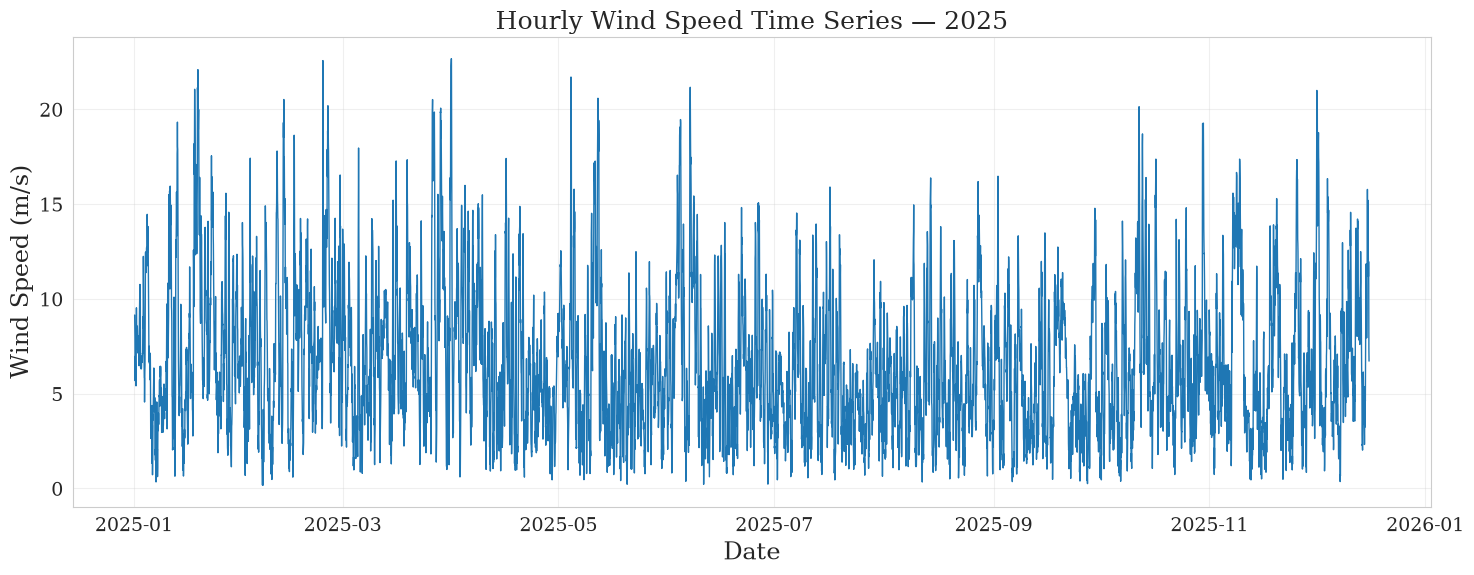

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# 1. LOAD DATA
# ============================================================

df = pd.read_csv(WIND_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst observations:")
display(df.head())

print("\nData types:")
print(df.dtypes)

# ============================================================
# 2. CREATE DATETIME INDEX
# ============================================================

df["year"] = 2025

df["datetime"] = pd.to_datetime(
    dict(
        year=df["year"],
        month=df["month"],
        day=df["day"],
        hour=df["hour"]
    ),
    errors="coerce"
)

df = df.sort_values("datetime").reset_index(drop=True)

# ============================================================
# 3. BASIC DATA QUALITY AUDIT
# ============================================================

print("Date range:")
print(df["datetime"].min(), "to", df["datetime"].max())

print("\nTotal observations:")
print(len(df))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate timestamps:")
print(df["datetime"].duplicated().sum())

print("\nWind speed descriptive statistics:")
print(df["windSpeed"].describe())

# ============================================================
# 4. CHECK TEMPORAL REGULARITY
# ============================================================

time_difference = df["datetime"].diff()

print("\nTimestamp interval distribution:")
print(time_difference.value_counts().head(10))

# ============================================================
# 5. CHECK PHYSICAL RANGE
# ============================================================

print("\nNegative wind-speed observations:")
print((df["windSpeed"] < 0).sum())

print("\nWind speeds above 30 m/s:")
print((df["windSpeed"] > 30).sum())

# ============================================================
# 6. SET DATETIME INDEX
# ============================================================

df = df.set_index("datetime")

# ============================================================
# 7. VISUALIZE FULL TIME SERIES
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df["windSpeed"],
    linewidth=1
)

plt.title("Hourly Wind Speed Time Series — 2025")
plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


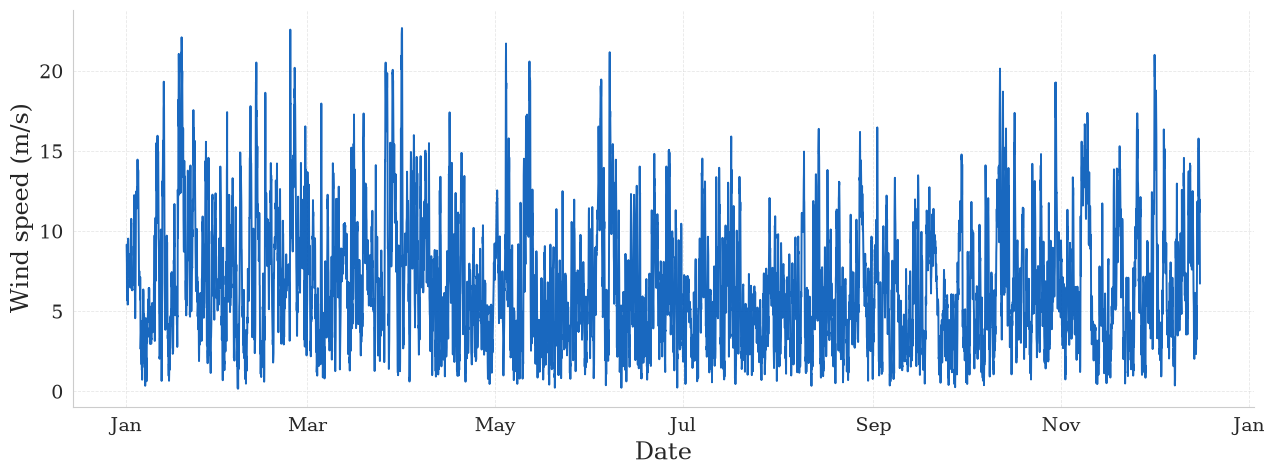

In [14]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if "datetime" in df.columns:
    dates = pd.to_datetime(df["datetime"])
else:
    dates = pd.to_datetime(
        dict(
            year=2025,
            month=df["month"],
            day=df["day"],
            hour=df["hour"]
        ),
        errors="coerce"
    )

wind_speed = df["windSpeed"]

plot_df = (
    pd.DataFrame({
        "dates": dates,
        "wind_speed": wind_speed
    })
    .dropna()
    .sort_values("dates")
)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    plot_df["dates"],
    plot_df["wind_speed"],
    color="#0057B8",
    linewidth=1.4,
    alpha=0.90,
)

ax.set_xlabel("Date")
ax.set_ylabel("Wind speed (m/s)")

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.45,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "wind.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "wind.png",
    dpi=600,
    bbox_inches="tight"
)


Start date: 2025-01-01 05:00:00
End date: 2025-12-16 03:00:00
Number of observations: 8375


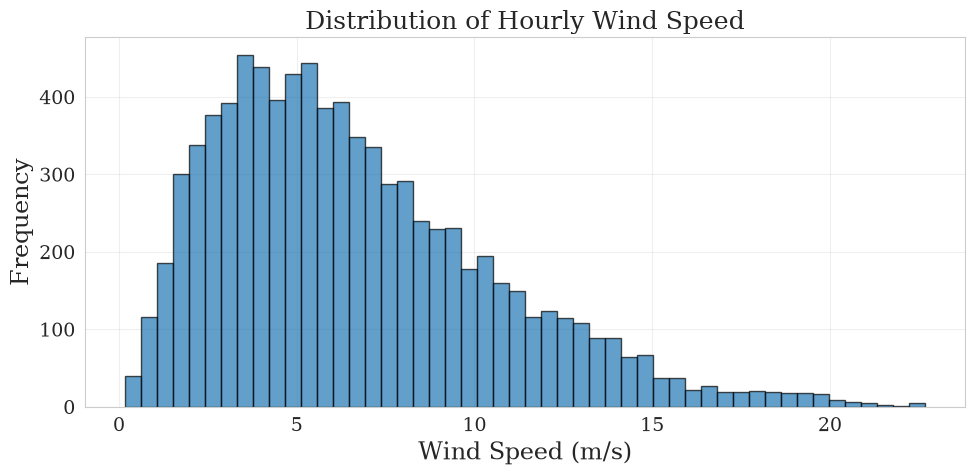

,mean,std,min,max
datetime,,,,
2025-01-31,7.798259,4.223814,0.343333,22.094000
2025-02-28,7.930807,4.229674,0.168000,22.572667
2025-03-31,7.807045,4.307833,0.801000,22.674000
2025-04-30,6.474715,3.541847,0.455000,17.409333
2025-05-31,6.109925,3.831465,0.222000,21.706000
2025-06-30,6.799312,4.035391,0.220000,21.164000
2025-07-31,5.309842,2.979732,0.451333,15.903500
2025-08-31,5.813795,3.259916,0.340000,16.380833
2025-09-30,5.515194,3.298405,0.255000,16.471333


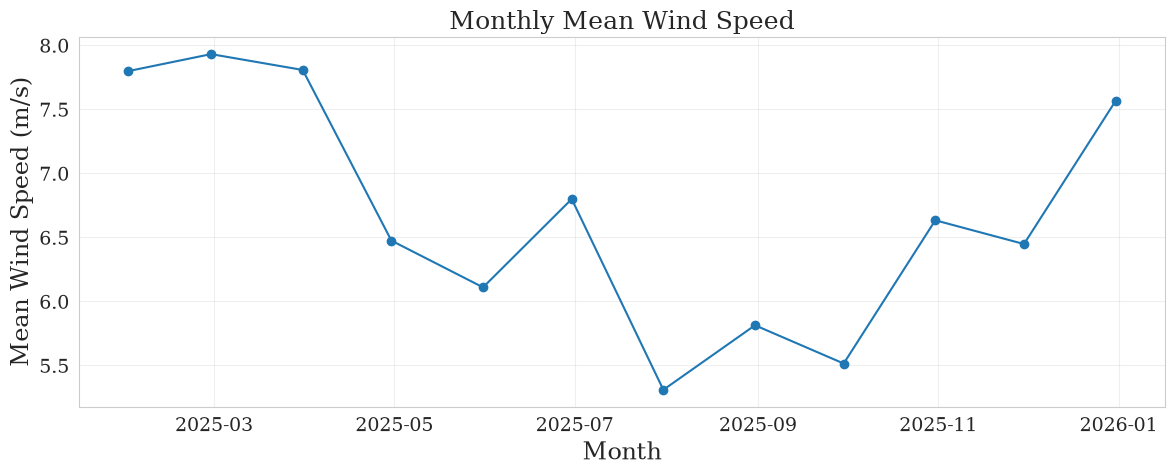

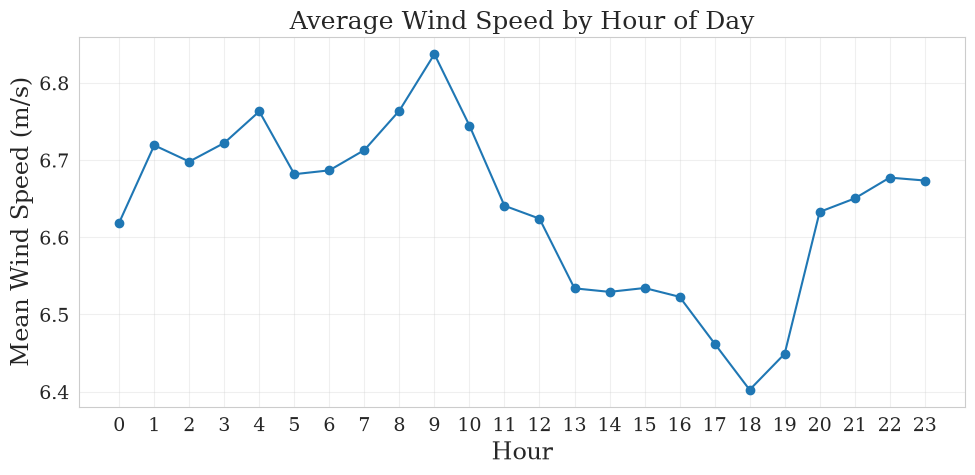

<Figure size 1200x500 with 0 Axes>

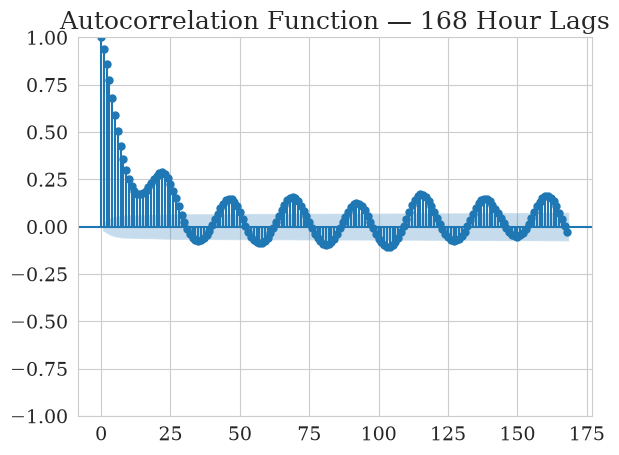

<Figure size 1200x500 with 0 Axes>

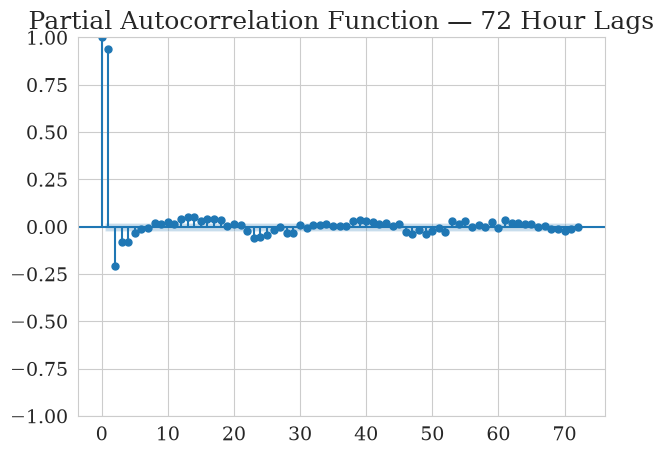

ADF Statistic: -14.114046450280616
p-value: 2.4906597456086077e-26

Critical Values:
1%: -3.4311337661638204
5%: -2.8618863704629427
10%: -2.566954368148624


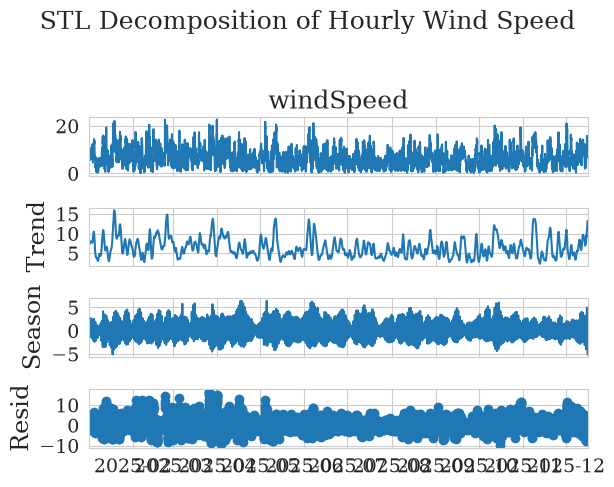

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# ============================================================
# 1. EXACT DATE RANGE
# ============================================================

print("Start date:", df.index.min())
print("End date:", df.index.max())
print("Number of observations:", len(df))


# ============================================================
# 2. WIND SPEED DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))

plt.hist(
    df["windSpeed"],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Hourly Wind Speed")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 3. MONTHLY WIND SPEED PATTERNS
# ============================================================

monthly_stats = df["windSpeed"].resample("ME").agg(
    ["mean", "std", "min", "max"]
)

display(monthly_stats)

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_stats.index,
    monthly_stats["mean"],
    marker="o"
)

plt.title("Monthly Mean Wind Speed")
plt.xlabel("Month")
plt.ylabel("Mean Wind Speed (m/s)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 4. HOURLY PATTERNS
# ============================================================

hourly_pattern = df.groupby(df.index.hour)["windSpeed"].mean()

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pattern.index,
    hourly_pattern.values,
    marker="o"
)

plt.title("Average Wind Speed by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Mean Wind Speed (m/s)")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 5. AUTOCORRELATION FUNCTION
# ============================================================

plt.figure(figsize=(12, 5))

plot_acf(
    df["windSpeed"],
    lags=168
)

plt.title("Autocorrelation Function — 168 Hour Lags")
plt.tight_layout()
plt.show()


# ============================================================
# 6. PARTIAL AUTOCORRELATION FUNCTION
# ============================================================

plt.figure(figsize=(12, 5))

plot_pacf(
    df["windSpeed"],
    lags=72,
    method="ywm"
)

plt.title("Partial Autocorrelation Function — 72 Hour Lags")
plt.tight_layout()
plt.show()


# ============================================================
# 7. AUGMENTED DICKEY-FULLER TEST
# ============================================================

adf_result = adfuller(df["windSpeed"].dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

print("\nCritical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")


# ============================================================
# 8. STL DECOMPOSITION
# ============================================================

stl = STL(
    df["windSpeed"],
    period=24,
    robust=True
)

result = stl.fit()

result.plot()

plt.suptitle(
    "STL Decomposition of Hourly Wind Speed",
    y=1.02
)

plt.tight_layout()
plt.show()

TRAIN
Observations: 5862
Period: 2025-01-01 05:00:00 to 2025-09-02 10:00:00

VALIDATION
Observations: 1256
Period: 2025-09-02 11:00:00 to 2025-10-24 18:00:00

TEST
Observations: 1257
Period: 2025-10-24 19:00:00 to 2025-12-16 03:00:00

PERSISTENCE BASELINE RESULTS
-----------------------------
MAE:   1.0374
RMSE:  1.3830
nRMSE: 0.0670
sMAPE: 19.83%
R²:    0.8805


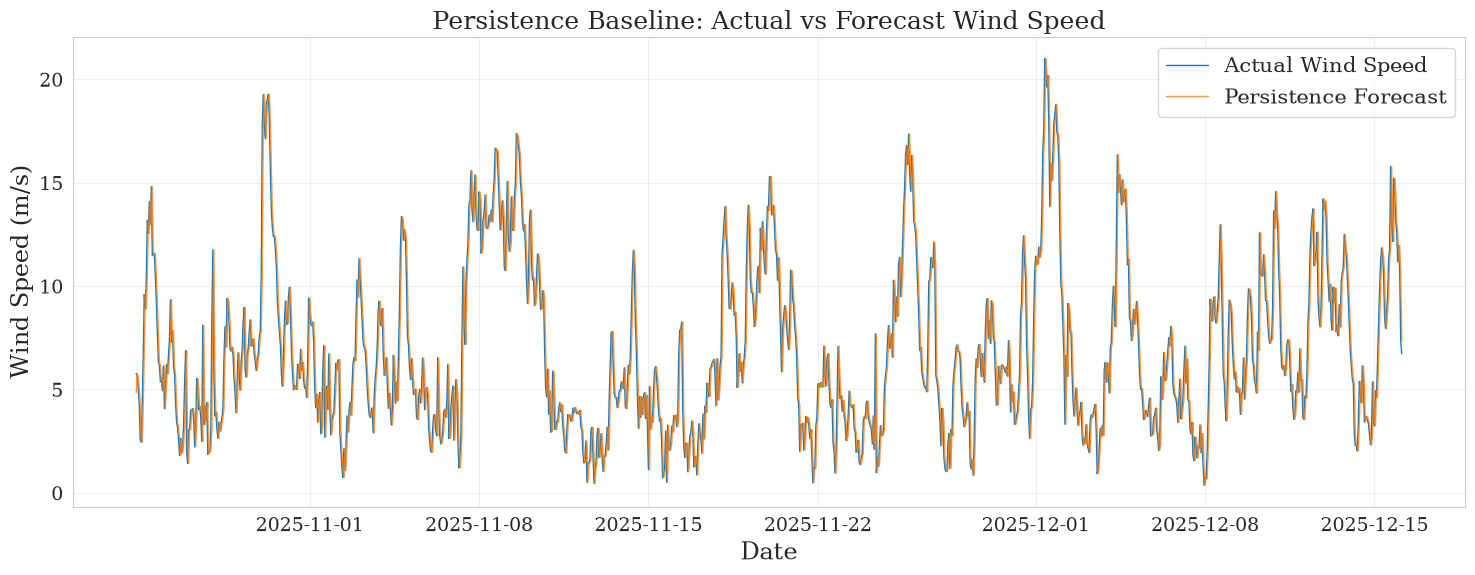

In [16]:
# ============================================================
# 1. CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("TRAIN")
print("Observations:", len(train_df))
print("Period:", train_df.index.min(), "to", train_df.index.max())

print("\nVALIDATION")
print("Observations:", len(val_df))
print("Period:", val_df.index.min(), "to", val_df.index.max())

print("\nTEST")
print("Observations:", len(test_df))
print("Period:", test_df.index.min(), "to", test_df.index.max())


# ============================================================
# 2. PERSISTENCE FORECAST
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Persistence:
# Forecast at time t = observed wind speed at time t-1

y_true = test_df["windSpeed"].iloc[1:].values
y_pred = test_df["windSpeed"].shift(1).iloc[1:].values


# ============================================================
# 3. EVALUATION METRICS
# ============================================================

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

r2 = r2_score(y_true, y_pred)

# Normalized RMSE using observed range

nrmse = rmse / (
    y_true.max() - y_true.min()
)

# Symmetric MAPE

smape = (
    100 *
    np.mean(
        2 * np.abs(y_pred - y_true) /
        (
            np.abs(y_true) +
            np.abs(y_pred) +
            1e-8
        )
    )
)


# ============================================================
# 4. RESULTS
# ============================================================

print("\nPERSISTENCE BASELINE RESULTS")
print("-----------------------------")

print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"nRMSE: {nrmse:.4f}")
print(f"sMAPE: {smape:.2f}%")
print(f"R²:    {r2:.4f}")


# ============================================================
# 5. VISUALIZATION
# ============================================================

plt.figure(figsize=(15, 6))

plt.plot(
    test_df.index[1:],
    y_true,
    label="Actual Wind Speed",
    linewidth=1
)

plt.plot(
    test_df.index[1:],
    y_pred,
    label="Persistence Forecast",
    linewidth=1,
    alpha=0.8
)

plt.title(
    "Persistence Baseline: Actual vs Forecast Wind Speed"
)

plt.xlabel("Date")
plt.ylabel("Wind Speed (m/s)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


# ============================================================
# EXPERIMENTAL CONFIGURATION
# ============================================================

CONTEXT_LENGTH = 168
FORECAST_HORIZON = 24

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15


# ============================================================
# EXTRACT WIND SPEED
# ============================================================

wind = df[["windSpeed"]].copy()

print("Total observations:", len(wind))
print("Start:", wind.index.min())
print("End:", wind.index.max())


# ============================================================
# CHRONOLOGICAL SPLIT BOUNDARIES
# ============================================================

n = len(wind)

train_end = int(n * TRAIN_RATIO)

val_end = int(
    n * (TRAIN_RATIO + VAL_RATIO)
)

print("\nSplit boundaries")

print("Train end index:", train_end)
print("Validation end index:", val_end)


# ============================================================
# FIT SCALER ONLY ON TRAINING DATA
# ============================================================

scaler = StandardScaler()

scaler.fit(
    wind.iloc[:train_end]
)


# ============================================================
# TRANSFORM COMPLETE SERIES
#
# This is safe because scaler was fitted only on training data.
# ============================================================

wind_scaled = scaler.transform(wind)


# ============================================================
# WINDOW CREATION FUNCTION
# ============================================================

def create_windows(
    data,
    context_length,
    forecast_horizon
):

    X = []
    y = []
    target_indices = []

    total_length = (
        context_length
        + forecast_horizon
    )

    for i in range(
        len(data) - total_length + 1
    ):

        # Historical context
        X.append(
            data[
                i:
                i + context_length
            ]
        )

        # Future 24-hour target
        y.append(
            data[
                i + context_length:
                i + total_length
            ]
        )

        # Store first target index
        target_indices.append(
            i + context_length
        )

    return (
        np.array(X),
        np.array(y),
        np.array(target_indices)
    )


# ============================================================
# CREATE ALL WINDOWS
# ============================================================

X, y, target_indices = create_windows(
    wind_scaled,
    CONTEXT_LENGTH,
    FORECAST_HORIZON
)


print("\nComplete window dataset")

print("X shape:", X.shape)
print("y shape:", y.shape)


# ============================================================
# ASSIGN WINDOWS CHRONOLOGICALLY
#
# Important:
# Assignment is based on target period,
# not merely the input starting position.
# ============================================================

train_mask = (
    target_indices
    + FORECAST_HORIZON
    <= train_end
)

val_mask = (
    (target_indices >= train_end)
    &
    (
        target_indices
        + FORECAST_HORIZON
        <= val_end
    )
)

test_mask = (
    target_indices >= val_end
)


# ============================================================
# CREATE FINAL DATASETS
# ============================================================

X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]


# ============================================================
# REMOVE FINAL SINGLETON DIMENSION FROM TARGET
# ============================================================

y_train = y_train.squeeze(-1)
y_val = y_val.squeeze(-1)
y_test = y_test.squeeze(-1)


# ============================================================
# FINAL SHAPES
# ============================================================

print("\nFINAL DATASETS")
print("----------------------------")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print()

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print()

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Total observations: 8375
Start: 2025-01-01 05:00:00
End: 2025-12-16 03:00:00

Split boundaries
Train end index: 5862
Validation end index: 7118

Complete window dataset
X shape: (8184, 168, 1)
y shape: (8184, 24, 1)

FINAL DATASETS
----------------------------
X_train: (5671, 168, 1)
y_train: (5671, 24)

X_val: (1233, 168, 1)
y_val: (1233, 24)

X_test: (1234, 168, 1)
y_test: (1234, 24)
